# Tutorial 4f: Three-Mirror Anastigmat (TMA)

This tutorial aims at demonstrating Optiland's capabilities in reflective systems design using freeform mirrors.

### Setup the telescope

The starting telescope is voluntarily defocused, it will be optimized after.

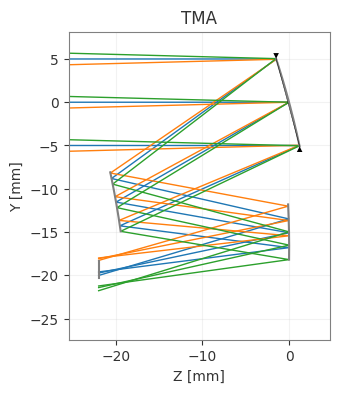

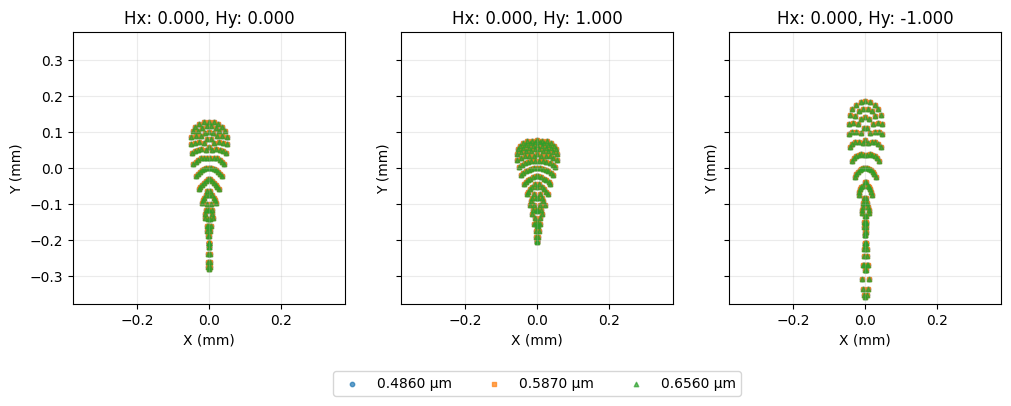

(<Figure size 1200x400 with 3 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: -1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [1]:
import numpy as np

from optiland import analysis, optic, optimization

focal_length = 100  # [mm]

lens = optic.Optic(name="TMA")
lens.set_aperture(aperture_type="EPD", value=10)
lens.fields.set_type(field_type="angle")
lens.fields.add(y=0)
lens.fields.add(y=+1.5)
lens.fields.add(y=-1.5)
lens.wavelengths.add(value=0.486)
lens.wavelengths.add(value=0.587, is_primary=True)
lens.wavelengths.add(value=0.656)

# The telescope is made of three freeform mirrors. We use XY-polynomial
# freeforms: a base conic plus a polynomial in x and y. Each mirror is tilted
# about x, so the system is symmetric about the y-z plane only.
lens.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
lens.surfaces.add(
    index=1,
    radius=-100,
    thickness=-20,
    conic=0,
    material="mirror",
    rx=np.radians(-15.0),
    is_stop=True,
    surface_type="polynomial",
    coefficients=[],
)
lens.surfaces.add(
    index=2,
    radius=-100,
    thickness=+20,
    conic=0,
    material="mirror",
    rx=np.radians(-10.0),
    dy=-11.5,
    surface_type="polynomial",
    coefficients=[],
)
lens.surfaces.add(
    index=3,
    radius=-100,
    thickness=-22,
    conic=0,
    material="mirror",
    rx=np.radians(-1.0),
    dy=-15,
    surface_type="polynomial",
    coefficients=[],
)
lens.surfaces.add(index=4, dy=-19.3)

# Note: lens.info() relies on paraxial ray tracing, which does not apply to a
# system of tilted, powered mirrors, so we inspect the system with real rays instead.
lens.draw(title=lens.name)
# lens.draw3D()
spot = analysis.SpotDiagram(lens)
spot.view()

## Optimization

The optimization variables are the radii, the mirror positions, decenters and tilts, the conic constants and the freeform coefficients.

We define constraints on the mirrors' decenters to prevent vignetting.

### Variables

In [2]:
problem = optimization.OptimizationProblem()

# radii
problem.add_variable(lens, "radius", surface_number=1, min_val=-1000, max_val=1000)
problem.add_variable(lens, "radius", surface_number=2, min_val=-1000, max_val=1000)
problem.add_variable(lens, "radius", surface_number=3, min_val=-1000, max_val=1000)

# mirror spacings
# In a folded system, a "thickness" variable would have to move every downstream
# surface along the folded beam path, which Optiland does not support. Instead we
# move M2, M3 and the image plane independently along the global z axis.
problem.add_variable(lens, "decenter", axis="z", surface_number=2, min_val=-35, max_val=-15)
problem.add_variable(lens, "decenter", axis="z", surface_number=3, min_val=-10, max_val=+10)
problem.add_variable(lens, "decenter", axis="z", surface_number=4, min_val=-40, max_val=-15)

# decenters
problem.add_variable(
    lens,
    "decenter",
    axis="y",
    surface_number=2,
    min_val=-15,
    max_val=-10,
)
problem.add_variable(
    lens,
    "decenter",
    axis="y",
    surface_number=3,
    min_val=-20,
    max_val=-11,
)
problem.add_variable(
    lens,
    "decenter",
    axis="y",
    surface_number=4,
    min_val=-28,
    max_val=-22,
)

# tilts
problem.add_variable(
    lens,
    "tilt",
    axis="x",
    surface_number=1,
    min_val=np.radians(-20.0),
    max_val=np.radians(-12.0),
)
problem.add_variable(
    lens,
    "tilt",
    axis="x",
    surface_number=2,
    min_val=np.radians(-15.0),
    max_val=np.radians(-08.0),
)
problem.add_variable(
    lens,
    "tilt",
    axis="x",
    surface_number=3,
    min_val=np.radians(-10.0),
    max_val=np.radians(+10.0),
)

# conic constants
problem.add_variable(lens, "conic", surface_number=1, min_val=-10, max_val=10)
problem.add_variable(lens, "conic", surface_number=2, min_val=-10, max_val=10)
problem.add_variable(lens, "conic", surface_number=3, min_val=-10, max_val=10)

# Freeform coefficients: x^2, y^2, x^2*y and y^3. Only even powers of x keep
# each mirror symmetric about the y-z plane, like the rest of the system.
for s in range(1, 4):
    for i, j in [(2, 0), (0, 2), (2, 1), (0, 3)]:
        problem.add_variable(
            lens,
            "polynomial_coeff",
            surface_number=s,
            coeff_index=(i, j),
            min_val=-1e-2,
            max_val=1e-2,
        )

### Operands

In [3]:
# Center M2 on its chief ray
input_data = {
    "optic": lens,
    "surface_number": 2,
    "Hx": 0,
    "Hy": 0,
    "Px": 0,
    "Py": 0,
    "wavelength": lens.wavelengths.primary_wavelength.value,
}
problem.add_operand(
    operand_type="real_y_intercept_lcs",
    target=0.0,
    weight=1,
    input_data=input_data,
)

# Center M3 on its chief ray
input_data = {
    "optic": lens,
    "surface_number": 3,
    "Hx": 0,
    "Hy": 0,
    "Px": 0,
    "Py": 0,
    "wavelength": lens.wavelengths.primary_wavelength.value,
}
problem.add_operand(
    operand_type="real_y_intercept_lcs",
    target=0.0,
    weight=1,
    input_data=input_data,
)

# Image surface - Real ray heights operands, in the lcs of the image surface
# Center the image surface on its chief ray
input_data = {
    "optic": lens,
    "surface_number": 4,
    "Hx": 0,
    "Hy": 0,
    "Px": 0,
    "Py": 0,
    "wavelength": lens.wavelengths.primary_wavelength.value,
}
problem.add_operand(
    operand_type="real_y_intercept_lcs",
    target=focal_length * np.tan(np.deg2rad(lens.fields.y_fields[0])),
    weight=1,
    input_data=input_data,
)
input_data = {
    "optic": lens,
    "surface_number": 4,
    "Hx": 0,
    "Hy": 1,
    "Px": 0,
    "Py": 0,
    "wavelength": lens.wavelengths.primary_wavelength.value,
}
problem.add_operand(
    operand_type="real_y_intercept_lcs",
    target=focal_length * np.tan(np.deg2rad(lens.fields.y_fields[1])),
    weight=1,
    input_data=input_data,
)
input_data = {
    "optic": lens,
    "surface_number": 4,
    "Hx": 0,
    "Hy": -1,
    "Px": 0,
    "Py": 0,
    "wavelength": lens.wavelengths.primary_wavelength.value,
}
problem.add_operand(
    operand_type="real_y_intercept_lcs",
    target=focal_length * np.tan(np.deg2rad(lens.fields.y_fields[2])),
    weight=1,
    input_data=input_data,
)

# RMS spot size - let's minimize the spot size for each field at the primary wavelength.
# We choose a 'uniform' distribution, so the number of rays actually means the rays on
# one axis. Therefore we trace ≈16^2 rays here.
for field in lens.fields.get_field_coords():
    input_data = {
        "optic": lens,
        "surface_number": 4,
        "Hx": field[0],
        "Hy": field[1],
        "num_rays": 16,
        "wavelength": 0.587,
        "distribution": "uniform",
    }
    problem.add_operand(
        operand_type="rms_spot_size",
        target=0.0,
        weight=10,
        input_data=input_data,
    )

problem.info()

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │                5.85255 │                 0 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type         │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ real y intercept lcs │    0     │              │              │        1 │             1 │  -0.043 │  -0.043 │           0.03 │
│  1 │ real y intercept lcs │    0     │              │              │        1 │             1 │  -0.086 │  -0.086 │           0.13 │
│  2 │ real y intercept lcs │    0     │              │          

### Optimization

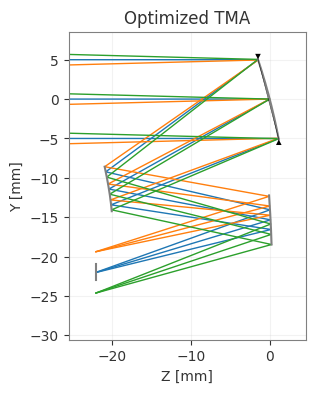

╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │              0.0106726 │           99.8176 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type         │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ real y intercept lcs │    0     │              │              │        1 │             1 │  -0.024 │  -0.024 │           5.3  │
│  1 │ real y intercept lcs │    0     │              │              │        1 │             1 │   0.015 │   0.015 │           2.11 │
│  2 │ real y intercept lcs │    0     │              │          

In [4]:
# Local optimizer
optimizer = optimization.OptimizerGeneric(problem)
res = optimizer.optimize(tol=1e-9)

# Global optimizer
# optimizer = optimization.DifferentialEvolution(problem)
# res = optimizer.optimize(maxiter=100, workers=-1)

lens.draw(title=f"Optimized {lens.name}")
problem.info()

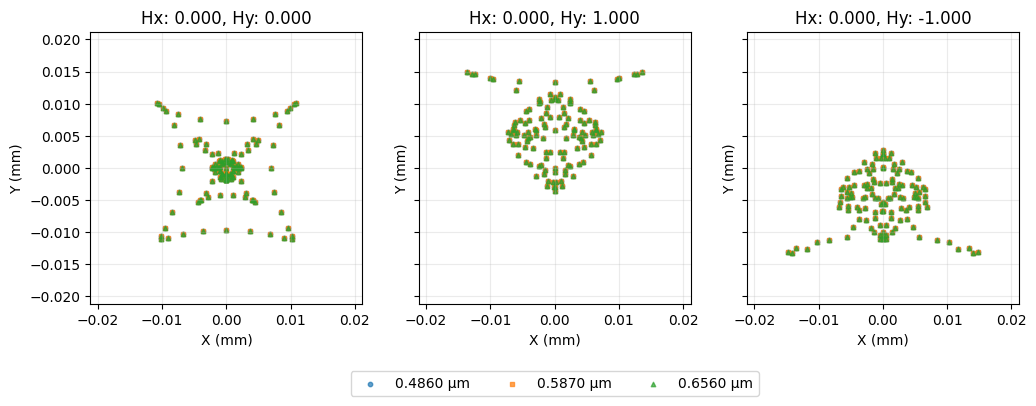

(<Figure size 1200x400 with 3 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: -1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [5]:
spot = analysis.SpotDiagram(lens)
spot.view()

## A note on first-order analysis

Every mirror in this telescope is tilted, so the system has no common optical axis. Paraxial (first-order) optics assumes one, which is why this tutorial avoids paraxial tools such as `lens.info()`, the `f2` operand and `GeometricMTF` (whose frequency cutoff comes from the paraxial f-number). Everything here, including the optimization, uses real rays, which handle tilted and decentered mirrors exactly.

For a centered mirror system where paraxial analysis does apply, see the [Cassegrain](../gallery/reflective/Cassegrain.ipynb) and [three-mirror anastigmat](../gallery/reflective/three_mirror_anastigmat.ipynb) gallery examples.